In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --- 0. STYLE CONFIGURATION ---
def matplotlib_default_config():
    font = {'family' : 'serif', 'weight' : 'normal', 'size' : 14}
    rcnew = {
        "mathtext.fontset" : "cm", "text.usetex": False, 'figure.frameon': True,
        'axes.linewidth': 2., "axes.titlesize" : 20, "axes.labelsize" : 20,
        "legend.fontsize" : 14, 'legend.fancybox': True, 'lines.linewidth': 2.5,
        'xtick.alignment': 'center', 'xtick.bottom': True, 'xtick.color': 'black',
        'xtick.direction': 'in', 'xtick.labelbottom': True, 'xtick.labelsize': 18,
        'xtick.major.bottom': True, 'xtick.major.pad': 6.0, 'xtick.major.size': 10.0,
        'xtick.major.width': 1.5, 'xtick.minor.bottom': True, 'xtick.minor.pad': 3.4,
        'xtick.minor.size': 5.0, 'xtick.minor.visible': True, 'xtick.minor.width': 1.0,
        'xtick.top': True, 'ytick.alignment': 'center_baseline', 'ytick.color': 'black',
        'ytick.direction': 'in', 'ytick.labelleft': True, 'ytick.labelsize': 18,
        'ytick.left': True, 'ytick.major.left': True, 'ytick.major.pad': 6.0,
        'ytick.major.size': 10.0, 'ytick.major.width': 1.5, 'ytick.minor.left': True,
        'ytick.minor.pad': 3.4, 'ytick.minor.right': True, 'ytick.minor.size': 5.0,
        'ytick.minor.visible': True, 'ytick.minor.width': 1.0, 'ytick.right': True
    }
    return font, rcnew

# Apply Config
%matplotlib widget 
font, rcnew = matplotlib_default_config()
plt.rc('font', **font)
plt.rcParams.update(rcnew)

In [35]:
# --- 1. DATA EXTRACTION ---
pkl_file_fid = "./Fiducial_452Halos_FullSpectra.pkl"
pkl_file_LH_0 = "./LH_0_452Halos_FullSpectra.pkl"
pkl_file_LH_1 = "./LH_1_452Halos_FullSpectra.pkl"
H_HUBBLE = 0.6774

df_all_fid  = pd.read_pickle(pkl_file_fid)
df_all_LH_0 = pd.read_pickle(pkl_file_LH_0)
df_all_LH_1 = pd.read_pickle(pkl_file_LH_1)


In [36]:
df_halos_fid = df_all_fid.drop_duplicates(subset=['halo_id'])
df_halos_LH_0 = df_all_LH_0.drop_duplicates(subset=['halo_id'])
df_halos_LH_1 = df_all_LH_1.drop_duplicates(subset=['halo_id'])




Masses_fid = df_halos_fid['halo_mass'].values
Masses_LH_0 = df_halos_LH_0['halo_mass'].values
Masses_LH_1 = df_halos_LH_1['halo_mass'].values

In [37]:
Masses_log10_fid = np.log10((Masses_fid * 1e10) / H_HUBBLE)
Masses_log10_LH_0 = np.log10((Masses_LH_0 * 1e10) / H_HUBBLE)
Masses_log10_LH_1 = np.log10((Masses_LH_1 * 1e10) / H_HUBBLE)

In [39]:
Masses_log10_fid.min(), Masses_log10_LH_0.min(), Masses_log10_LH_1.min()

(10.593893, 9.832725, 9.949782)

In [40]:
Masses_log10_fid.max(), Masses_log10_LH_0.max(), Masses_log10_LH_1.max()

(15.015921, 15.0302925, 15.036266)

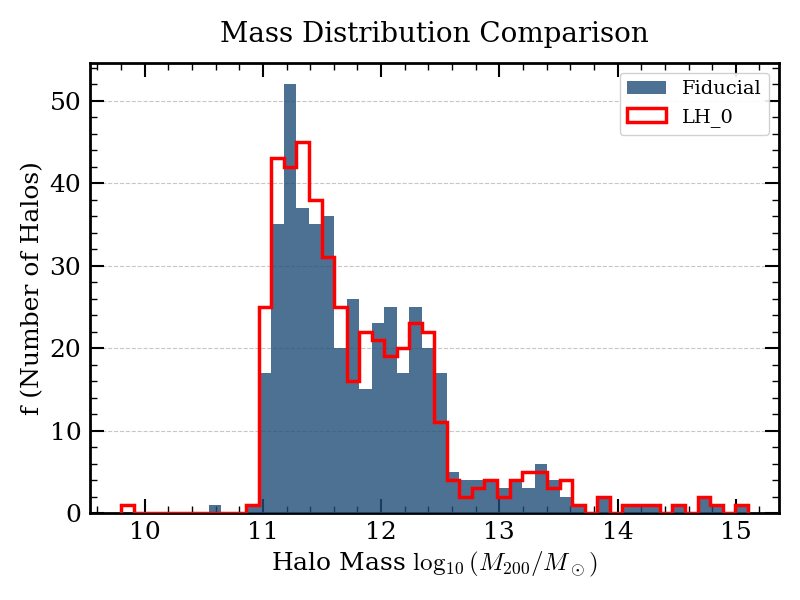

In [68]:
fig, ax = plt.subplots(figsize=(8, 6))

# Plotting only the top lines using histtype='step'
# zorder=3 ensures the lines stay in front of the grid
counts_fid, bins_fid, _ = ax.hist(Masses_log10_fid, bins=50, range=[9.8, 15.1], 
                                  color='#1f4e78', alpha = 0.8,
                                  linewidth=2.5, label='Fiducial', zorder=3)

counts_LH_0, bins_LH_0, _ = ax.hist(Masses_log10_LH_0, bins=50, range=[9.8, 15.1], histtype='step', color='red', linewidth=2.5, label='LH_0', zorder=3)

#counts_LH_1, bins_LH_1, _ = ax.hist(Masses_log10_LH_1, bins=50, range=[9.8, 15.1], histtype='step', color='green', linewidth=2.5, label='LH_1', zorder=3)

# Axes formatting
ax.set_xlabel(r'Halo Mass $\log_{10}(M_{200} / M_\odot)$', fontsize=18)
ax.set_ylabel('f (Number of Halos)', fontsize=18)
ax.set_title('Mass Distribution Comparison', fontsize=20, pad=15) # Updated title

# Add grid only on Y axis for readability
ax.grid(axis='y', linestyle='--', alpha=0.7, zorder=0)

# Add a legend to identify the 3 lines
ax.legend(loc='upper right', fontsize=14, framealpha=0.9)

plt.tight_layout()
plt.show()